In [1]:
import pandas as pd 

In [2]:
df = pd.read_excel(r"C:\\Order Orchestration code\\Original_files\\OPEN ORDER 17072026.XLSX", sheet_name=1, engine='openpyxl')

In [3]:
df.shape

(42381, 28)

In [4]:
df.columns

Index(['CustomerStatus', 'Date', 'OrderType', 'Salesdocument', 'Delivery',
       'Item(SD)', 'Time', 'SalesDocumentType', 'Plant', 'Material',
       'MaterialDescription', 'EAN/UPC', 'OpenOrderQty.', 'OpenDel.Qty.',
       'OpenBillQty.', 'Customer', 'Name1', 'DocumentDate', 'Time.1',
       'NetPrice', 'NetPrice.1', 'ExchangeRate', 'TotalorderQuantity',
       'TotalValueMINR', 'KIT', 'KITNon', 'CustomerType', 'CreditBlock'],
      dtype='str')

In [6]:
open_order_df = df[['CustomerStatus','Date','Time','SalesDocumentType','Plant','Material','MaterialDescription','EAN/UPC','OpenOrderQty.','Customer','Name1','DocumentDate','Time.1']]

In [7]:
open_order_df = open_order_df.rename(columns={'CustomerStatus':'is_credit_block','Date':'date','Time':'time','SalesDocumentType':'order_type','Plant':'ordered_plant','Material':'material_code','MaterialDescription':'material_descp','EAN/UPC':'color_code','OpenOrderQty.':'open_order_qty','Customer':'customer_code','Name1':'customer_name','DocumentDate':'ordered_date','Time.1':'ordered_time'})

In [8]:
open_order_df.columns

Index(['is_credit_block', 'date', 'time', 'order_type', 'ordered_plant',
       'material_code', 'material_descp', 'color_code', 'open_order_qty',
       'customer_code', 'customer_name', 'ordered_date', 'ordered_time'],
      dtype='str')

In [9]:
print("Number of unique customers:", open_order_df['customer_code'].nunique())
print("Number of unique materials:", open_order_df['material_code'].nunique())
print("Number of unique plants:", open_order_df['ordered_plant'].nunique())
print("Number of unique order types:", open_order_df['order_type'].nunique())

Number of unique customers: 670
Number of unique materials: 8320
Number of unique plants: 12
Number of unique order types: 13


In [10]:
def missing_report(df):
    report = pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_pct": (df.isna().sum()/len(df)*100).round(2).values
    })
    return report.sort_values("missing_count", ascending=False)

missing_report(open_order_df)

,column,missing_count,missing_pct
0,is_credit_block,29015,68.46
7,color_code,450,1.06
1,date,0,0.00
3,order_type,0,0.00
2,time,0,0.00
4,ordered_plant,0,0.00
5,material_code,0,0.00
6,material_descp,0,0.00
8,open_order_qty,0,0.00
9,customer_code,0,0.00


Missing value reasons : 
is_credit_block missing values are the customers which are not in credit block defined #N/A
Blank order colors are the manual orders 

In [11]:
print(f"Orders: {open_order_df.duplicated().sum()} duplicate rows")

Orders: 15 duplicate rows


In [17]:
duplicate_rows = open_order_df[open_order_df.duplicated()]
print("Duplicate rows:")
print(duplicate_rows)

Duplicate rows:
      is_credit_block       date       time order_type  ordered_plant  \
230               NaN 2026-07-17  8:10:02AM       ZEOR           1110   
2949               CB 2026-07-17  8:10:04AM       ZMSO           1157   
3289              NaN 2026-07-17  8:10:02AM       ZMSO           1155   
3789              NaN 2026-07-17  8:10:04AM       ZMSO           1161   
3800              NaN 2026-07-17  8:10:04AM       ZMSO           1161   
3831              NaN 2026-07-17  8:10:04AM       ZMSO           1161   
4007              NaN 2026-07-17  8:10:04AM       ZROH           1110   
4628              NaN 2026-07-17  8:10:04AM       ZROH           1141   
6190               CB 2026-07-17  8:10:04AM       ZFMO           1153   
8597              NaN 2026-07-17  8:10:02AM       ZROH           1155   
9328              NaN 2026-07-17  8:10:04AM       ZMSO           1110   
11481             NaN 2026-07-17  8:10:04AM       ZMSO           1156   
11553             NaN 2026-07-17  8

In [16]:
open_order_df.shape

(42381, 13)

In [ ]:
# print(open_order_df["order_type"].value_counts())

order_type_summary = (
    open_order_df
    .groupby("order_type")
    .agg(
        order_lines=("open_order_qty","count"),
        order_qty=("open_order_qty","sum")
    )
    .reset_index()
)

print(order_type_summary)

   order_type  order_lines  order_qty
0        ZACC          512        620
1        ZCFF            2          3
2        ZCOR           28        152
3        ZEOR         3180      11695
4        ZFMO         8867      16074
5        ZLOB          151          0
6        ZMSO        27554     182253
7        ZORM            3          3
8        ZOVS           24      26063
9        ZROH         1928      40117
10       ZROP          126        243
11       ZTEP            3          0
12       ZTES            3          0


In [19]:
required_order_types = [
    "ZFMO",
    "ZMSO",
    "ZEOR",
    "ZROH",
    "ZROP",
    "ZACC"
]

open_order_df = open_order_df[
    open_order_df["order_type"].isin(required_order_types)
].copy()

In [21]:
order_type_summary = (
    open_order_df
    .groupby("order_type")
    .agg(
        order_lines=("open_order_qty","count"),
        order_qty=("open_order_qty","sum")
    )
    .reset_index()
)

print(order_type_summary)

  order_type  order_lines  order_qty
0       ZACC          512        620
1       ZEOR         3180      11695
2       ZFMO         8867      16074
3       ZMSO        27554     182253
4       ZROH         1928      40117
5       ZROP          126        243


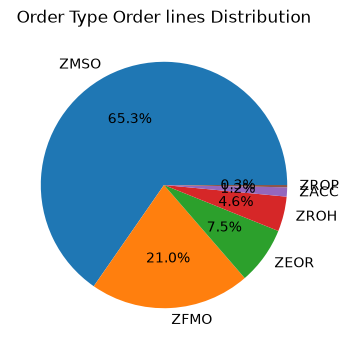

In [23]:
import matplotlib.pyplot as plt

(
    open_order_df["order_type"]
    .value_counts()
    .plot(
        kind="pie",
        autopct="%1.1f%%",
        figsize=(4,4)
    )
)

plt.ylabel("")
plt.title("Order Type Order lines Distribution")
plt.show()

In [29]:
top_materials = (
    open_order_df
    .groupby(["material_code", "material_descp"])["open_order_qty"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_materials)

material_code  material_descp                     
IA226215       Loctite638                             125000
IM301276L      EicherPremiumPlusGrease                 32400
IM300205       EICHERPREMIUMCOOLANT                     5680
IA303162       FRONTREFLECTIVETAPEWHITE(50MMWIDTH)      2500
IM301267L      EicherZFECOFLUIDTMOIL-10Ltrs             1100
ID637271       ADBLUEBACKFLOWCONNECTORKIT               1086
IE314595       CABLETIE-HARNESSCLIPS                    1080
IB002785       PLATETHRUST(STD)                          867
IC357820       KITBRAKELINING(410X180)(STD)STH           639
IE302372       980881Engineharnessclip                   620
Name: open_order_qty, dtype: int64


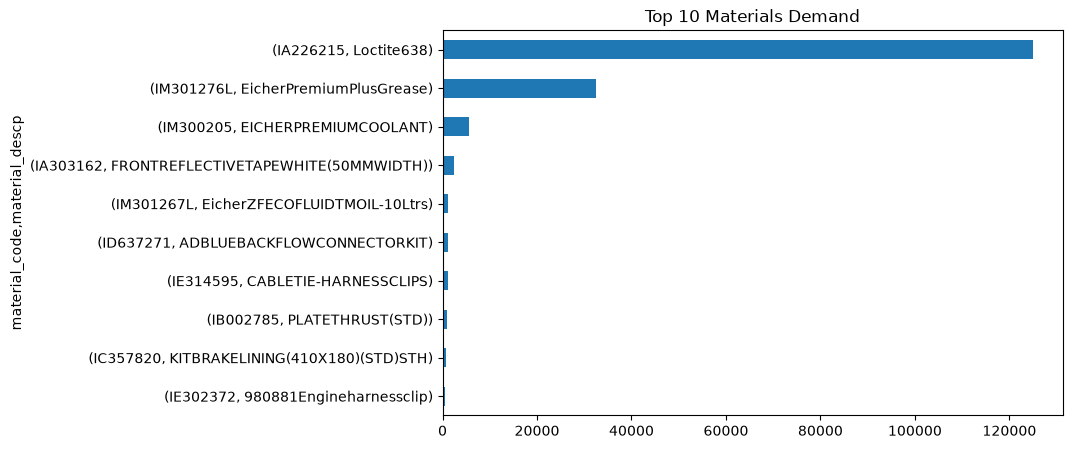

In [30]:
top_materials.sort_values().plot(
    kind="barh",
    figsize=(8,5)
)

plt.title("Top 10 Materials Demand")
plt.show()

In [35]:
dealer_demand = (
    open_order_df
    .groupby(["customer_code", "customer_name"])["open_order_qty"]
    .sum()
    .sort_values(ascending=False)
)

top20_dealers = dealer_demand.head(10)

print(top20_dealers)

customer_code  customer_name              
1S4044         AnamallaisAgencies(Stadium)    62581
1S7091         VECommercialVehiclesLtd        62556
1S1148         SincereMarketingServicesPvt    32424
1S3470         UniconMotorsPrivateLimited      4284
1S3390         UNICONMOTORSPVT.LTD.            3546
1S6189         LPFAgenciesLLP                  2149
1S7177         PunjabMobilityPrivateLimite     1973
1S6098         AUTOMOTIVEMARKETINGPVT.LTD      1971
1S2040         DAGAAUTODISTRIBUTORS            1497
1S3393         THOLIAMOTORSPVT.LTD.            1385
Name: open_order_qty, dtype: int64


In [65]:
total_qty = dealer_demand.sum()

top10_pct = (
    dealer_demand.head(10).sum()
    / total_qty * 100
)

print(
    f"Top 10 dealers contribute {top10_pct:.2f}% demand"
)

Top 10 dealers contribute 74.09% demand


In [34]:
# Material-wise dealer quantity
material_dealer_qty = (
    open_order_df
    .groupby(["material_code", "material_descp", "customer_code"])["open_order_qty"]
    .sum()
    .reset_index()
)

# Dealer with maximum qty for each material
top_dealer_per_material = (
    material_dealer_qty.loc[
        material_dealer_qty.groupby(
            ["material_code", "material_descp"]
        )["open_order_qty"].idxmax()
    ]
)

# Top 10 materials overall
top_materials = (
    open_order_df
    .groupby(["material_code", "material_descp"])["open_order_qty"]
    .sum()
    .reset_index()
    .sort_values("open_order_qty", ascending=False)
    .head(10)
)

# Merge with top dealer info
result = top_materials.merge(
    top_dealer_per_material,
    on=["material_code", "material_descp"],
    suffixes=("_material_total", "_dealer")
)

print(result)

  material_code                       material_descp  \
0      IA226215                           Loctite638   
1     IM301276L              EicherPremiumPlusGrease   
2      IM300205                 EICHERPREMIUMCOOLANT   
3      IA303162  FRONTREFLECTIVETAPEWHITE(50MMWIDTH)   
4     IM301267L         EicherZFECOFLUIDTMOIL-10Ltrs   
5      ID637271           ADBLUEBACKFLOWCONNECTORKIT   
6      IE314595                CABLETIE-HARNESSCLIPS   
7      IB002785                     PLATETHRUST(STD)   
8      IC357820      KITBRAKELINING(410X180)(STD)STH   
9      IE302372              980881Engineharnessclip   

   open_order_qty_material_total customer_code  open_order_qty_dealer  
0                         125000        1S4044                  62500  
1                          32400        1S1148                  32220  
2                           5680        1S6239                    200  
3                           2500        1S3390                   2500  
4                      

In [106]:
credit_summary = (
    open_order_df.groupby('Customer')
    ["CustomerStatus"]
    .value_counts()
)

print(credit_summary)

Customer  CustomerStatus
1E150427  CB                  3
1E150523  CB                  1
1S1007    CB                 94
1S1021    CB                143
1S1022    CB                283
                           ... 
1S7060    CB                 90
1S7069    CB                 72
1S7076    CB                151
1S7087    CB                 78
1S7097    CB                150
Name: count, Length: 102, dtype: int64


In [108]:
open_order_df.columns

Index(['CustomerStatus', 'Date', 'SalesDocumentType', 'Plant', 'Material',
       'MaterialDescription', 'EAN/UPC', 'OpenOrderQty.', 'Customer', 'Name1',
       'DocumentDate', 'Time.1'],
      dtype='str')

In [47]:
# Keep only valid dealers
open_order_df = open_order_df[
    open_order_df["customer_code"].astype(str).str.startswith("1S", na=False)
]

print("Remaining rows:", len(open_order_df))

Remaining rows: 42142


Invenotry with ageing invenotory by plant 

In [55]:
df1= pd.read_excel(r"C:\Order Orchestration code\Original_files\Ageing inventory may'26.xlsb",sheet_name="Ageing", engine='pyxlsb')

In [56]:
df1.columns

Index([      'Unnamed: 0',       'Unnamed: 1',       'Unnamed: 2',
             'Unnamed: 3',       'Unnamed: 4', 2533.3235150683095,
                   '0-30',            '31-60',            '61-90',
                 '91-180',      'Unnamed: 10',      'Unnamed: 11',
                '181-365',      'Unnamed: 13',      'Unnamed: 14',
            'Unnamed: 15',      'Unnamed: 16',      'Unnamed: 17',
            'Unnamed: 18',      'Unnamed: 19',      'Unnamed: 20',
            'Unnamed: 21',  618.0668572537878,      'Unnamed: 23',
            'Unnamed: 24',      'Unnamed: 25',      'Unnamed: 26',
            'Unnamed: 27',      'Unnamed: 28'],
      dtype='object')

In [57]:
df1.columns = df1.iloc[0]
df1 = df1.iloc[1:].copy()

# Reset index
df1 = df1.reset_index(drop=True)

In [58]:
df1.columns

Index(['Plant', 'Material Code', 'Material Description', 'MAP', 'Plant Stock',
       'Total usage value', 'MAY2026', 'APR2026', 'MAR2026', 'FEB2026',
       'JAN2026', 'DEC2025', 'NOV2025', 'OCT2025', 'SEP2025', 'AUG2025',
       'JUL2025', 'JUN2025', '> 1', '> 2', '> 3', '>1 Qty', '> 1 MINR',
       'Total', 'Diff', 'Transit', 'Stk', 'P/ NP', 'Location'],
      dtype='object', name=0)

In [59]:
df1.shape

(215515, 29)

In [85]:
ageing_df = df1[['Plant', 'Material Code','Material Description', 'Plant Stock','> 1', '> 2', '> 3']]

In [86]:
ageing_df.describe()

,Plant,Material Code,Material Description,Plant Stock,> 1,> 2,> 3
count,215515,215515,215515,215515,215515,215515,215515
unique,10,47951,32816,2064,618,461,503
top,1110,RIBBON01,GASKET,2,0,0,0
freq,46723,10,726,61194,150209,190377,206849


In [87]:
ageing_df.rename(columns={'Plant Stock': 'Total Stock','Material Code':'material_code','Material Description':'material_description','> 1': 'Ageing_1', '> 2': 'Ageing_2', '> 3': 'Ageing_3'}, inplace=True)

In [66]:
missing_report(ageing_df)

,column,missing_count,missing_pct
0,Plant,0,0.0
1,Material Code,0,0.0
2,Total Stock,0,0.0
3,Ageing_1,0,0.0
4,Ageing_2,0,0.0
5,Ageing_3,0,0.0


In [67]:
 
print(
    f"Ageing DataFrame: {ageing_df.duplicated().sum()} duplicate rows"
)
 

Ageing DataFrame: 0 duplicate rows


In [69]:
plant_inventory = (
    ageing_df
    .groupby("Plant")["Total Stock"]
    .sum()
    .sort_values(ascending=False)
)

print(plant_inventory)

Plant
1110    8279552.645
1155         866517
1153       749324.1
1152      499459.06
1156      486215.45
1158         389517
1159         272253
1157         245726
1161         203531
1160             10
Name: Total Stock, dtype: object


In [70]:
ageing_df.columns

Index(['Plant', 'Material Code', 'Total Stock', 'Ageing_1', 'Ageing_2',
       'Ageing_3'],
      dtype='str', name=0)

In [71]:
print(
    ageing_df["Ageing_1"]
    .sum()
)

1047130.8


In [73]:
print(
    ageing_df["Ageing_2"]
    .sum()
)

517878


In [74]:
print(
    ageing_df["Ageing_3"]
    .sum()
)

628846


In [88]:
ageing_df['ageing_stock'] = ageing_df["Ageing_1"] + ageing_df["Ageing_2"] + ageing_df["Ageing_3"]

In [76]:
ageing_df['ageing_stock'].sum()

2193854.8

In [78]:
ageing_df['Total Stock'].sum()

11992105.254999999

In [96]:
(ageing_df['ageing_stock'].sum()/ageing_df['Plant Stock'].sum())*100

18.29415897667586

In [79]:
ageing_by_plant = (
    ageing_df
    .groupby("Plant")
    [["Total Stock","ageing_stock"]]
    .sum()
)

print(ageing_by_plant)

0      Total Stock ageing_stock
Plant                          
1110   8279552.645    1657417.3
1152     499459.06        66948
1153      749324.1     123708.5
1155        866517       138010
1156     486215.45        69617
1157        245726        30846
1158        389517        28282
1159        272253        55459
1160            10            0
1161        203531        23567


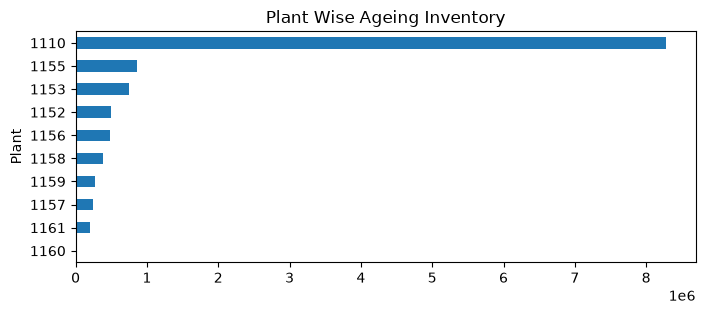

In [80]:
(
    ageing_by_plant["Total Stock"]
    .sort_values()
    .plot(
        kind="barh",
        figsize=(8,3)
    )
)

plt.title(
    "Plant Wise Ageing Inventory"
)

plt.show()

In [81]:
ageing_df.columns

Index(['Plant', 'Material Code', 'Total Stock', 'Ageing_1', 'Ageing_2',
       'Ageing_3', 'ageing_stock'],
      dtype='str', name=0)

In [94]:
# Total ageing stock by material
top_materials = (
    ageing_df
    .groupby("material_description")["ageing_stock"]
    .sum()
    .reset_index()
    .sort_values("ageing_stock", ascending=False)
    .head(10)
)

# Plant-wise ageing stock by material
material_plant_ageing = (
    ageing_df
    .groupby(["material_description", "Plant"])["ageing_stock"]
    .sum()
    .reset_index()
)

# Plant with maximum ageing stock for each material
top_plant_per_material = material_plant_ageing.loc[
    material_plant_ageing.groupby("material_description")["ageing_stock"].idxmax()
]

# Combine
result = top_materials.merge(
    top_plant_per_material,
    on="material_description",
    suffixes=("_total", "_plant")
)
print(result.to_csv(sep="\t", index=False))
print(result)

material_description	ageing_stock_total	Plant	ageing_stock_plant
Fragile Stickers	33208	1156	33208
NUT,CON ROD	27433	1110	27389
Sikaflex 258 EP	24000	1110	24000
KIT STICKER	20796	1159	20796
NUT WELD 8	16538	1110	16432
HEXAGON SCREWS M14X1.50X46	15935	1110	15828
FLANGE SCREWS M16*2.00*50	15660	1110	15604
BUSH	15547	1155	8293
POLY -5 X 45	15044	1155	8000
SCREW M6x12X1	13923	1152	9124

         material_description ageing_stock_total  Plant ageing_stock_plant
0            Fragile Stickers              33208   1156              33208
1                 NUT,CON ROD              27433   1110              27389
2             Sikaflex 258 EP              24000   1110              24000
3                 KIT STICKER              20796   1159              20796
4                  NUT WELD 8              16538   1110              16432
5  HEXAGON SCREWS M14X1.50X46              15935   1110              15828
6   FLANGE SCREWS M16*2.00*50              15660   1110              15604
7             

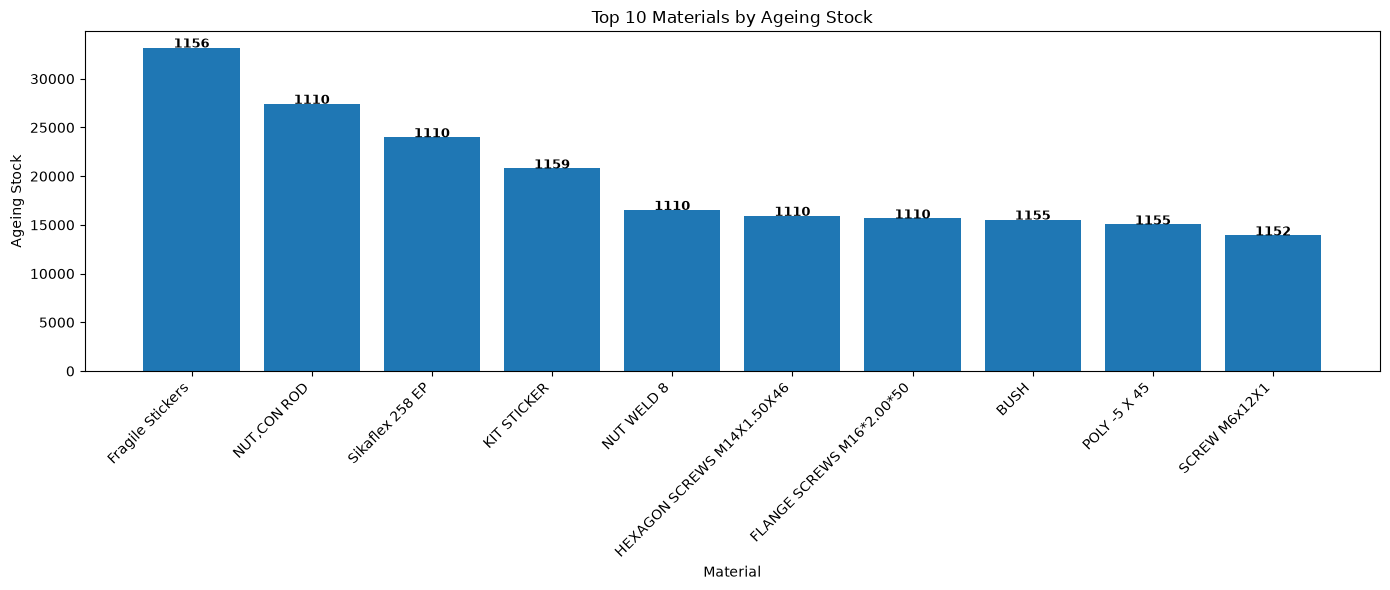

In [93]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

bars = plt.bar(
    result["material_description"],
    result["ageing_stock_total"]
)

for bar, plant in zip(bars, result["Plant"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(plant),
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Top 10 Materials by Ageing Stock")
plt.ylabel("Ageing Stock")
plt.xlabel("Material")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [95]:
moq_df = pd.read_excel(r"C:\Order Orchestration code\Original_files\sales MOQ qty.XLSX", engine='openpyxl')

In [96]:
moq_df.shape

(112564, 20)

In [98]:
moq_df.columns

Index(['Material', 'Material Description', 'Plant', 'Exclusion',
       'Replenish Code', 'Replaced with', 'M.O.Q', 'Mat.Type', 'MAP',
       'NET OK Stk', 'Stock W110', 'Stock W170', 'Net OK W120', 'Stock V110',
       'Stock V170', 'Net OK V120', 'Final Stock', 'Net Wt', 'Gross Wt',
       'Avg.NDP'],
      dtype='str')

In [99]:
open_order_df.columns

Index(['is_credit_block', 'date', 'time', 'order_type', 'ordered_plant',
       'material_code', 'material_descp', 'color_code', 'open_order_qty',
       'customer_code', 'customer_name', 'ordered_date', 'ordered_time'],
      dtype='str')

In [100]:
missing_moq = (
    set(open_order_df["material_code"])
    - set(moq_df["Material"])
)

print(
    "Missing MOQ:",
    len(missing_moq)
)

Missing MOQ: 5


In [103]:
missing_moq = (
    set(open_order_df["material_code"])
    - set(moq_df["Material"])
)

print("Missing MOQ Materials:")
print(missing_moq)

Missing MOQ Materials:
{'ID370681', 'IC501357', 'IC379952', 'ID633087', 'IC379953'}


In [105]:
missing_moq_df = (
    open_order_df[
        open_order_df["material_code"].isin(missing_moq)
    ][["material_code", "material_descp"]]
    .drop_duplicates()
    .sort_values("material_code")
)
print(
    missing_moq_df.to_csv(
        sep="\t",
        index=False
    )
) 

material_code	material_descp
IC379952	LeafSpringParts
IC379953	LeafSpringParts
IC501357	REPAIRKIT
ID370681	HEXAGONSCREW
ID633087	FROSTCOMPENSATIONDIAPHRAGM



In [106]:
vor_df = pd.read_excel(r"C:\Order Orchestration code\Original_files\Max_qty_VOR.xlsx", engine='openpyxl')

In [107]:
vor_df.shape

(11895, 6)

In [108]:
vor_df.head()

,Material,Material Description,Dlv.Qty,User Name,Date,Time
0,152144,MECH.TOOL VALVE STEM SEAL INSTALLER,1,VHEMBROM1,10.07.2025,09:14:35
1,152593,MECH.TOOL PITMAN ARM PULLER,1,VHEMBROM1,07.01.2026,12:19:00
2,153164,MECH.TOOL CYL.GAUGE,1,VHEMBROM1,07.01.2026,12:19:00
3,153463,MECH.TOOL BEARING PULLER AND INSTALLER,1,VHEMBROM1,07.01.2026,12:19:00
4,153801,MECH.TOOL BYE-PASS OIL FILTER WRENCH,1,VHEMBROM1,07.01.2026,12:19:00


GIT DATA cleaning and analysis 

In [85]:
import pandas as pd 

In [86]:
git_vepdc = pd.read_excel(r"C:\Order Orchestration code\Original_files\Open ASN 080926.xlsx",sheet_name=1,engine='openpyxl')

In [87]:
git_vepdc.shape

(107501, 26)

In [88]:
git_vepdc.columns

Index(['Sch.No.   ', 'ItmNo.', 'Plant', 'Storage Loc.', 'CC Key', 'WSN No.   ',
       'IBD No.   ', 'IBD Date  ', 'ASN Flag', 'Challan No.     ',
       'Challan Date', 'Material    ',
       'Material Description                    ', 'Vendor    ',
       'Vendor Name                        ', 'GE No.     ', 'GE Date.',
       'GE Time.', 'GR No.    ', 'GR Date.  ', 'GR Time.', '           Qty',
       '        MAP', 'Inventory Value', 'Delivery Status',
       'Status desc       '],
      dtype='str')

In [89]:
git_vepdc = git_vepdc.rename(columns={
    'Plant':'plant',
    'Storage Loc.':'storage_location',
    'IBD Date  ':'ibd_date',
    'Material    ':'material_code',
    'Material Description                    ':'material_description',
    'Vendor':'vendor_code',
    'Vendor Name                        ':'vendor_description',
    '         Qty':'asn_qty',
    'Delivery Status':'delivery_status',
    'Status desc       ':'status_description',
})

In [90]:
git_vepdc.columns

Index(['Sch.No.   ', 'ItmNo.', 'plant', 'storage_location', 'CC Key',
       'WSN No.   ', 'IBD No.   ', 'ibd_date', 'ASN Flag', 'Challan No.     ',
       'Challan Date', 'material_code', 'material_description', 'Vendor    ',
       'vendor_description', 'GE No.     ', 'GE Date.', 'GE Time.',
       'GR No.    ', 'GR Date.  ', 'GR Time.', '           Qty', '        MAP',
       'Inventory Value', 'delivery_status', 'status_description'],
      dtype='str')

In [91]:
git_vepdc = git_vepdc[git_vepdc['delivery_status'].isin([1,2,3])]

In [92]:
git_vepdc['status_description'].unique()

<StringArray>
['In Transit        ', 'In Warehouse      ', 'Despatched to VECV']
Length: 3, dtype: str

In [93]:
git_vepdc['storage_location'].unique()

array(['W110        ', 'V110        ', 4101, 4103, 5201, 5301, 5401, 5403,
       5501, 5502, 5503, 5601, 5701, 5801, 5901, 6001, 6101], dtype=object)

In [94]:
git_vepdc['ibd_date'].min()

Timestamp('2019-08-07 00:00:00')

In [95]:
git_vepdc['ibd_date'].max()

Timestamp('2026-09-08 00:00:00')

In [96]:
git_vepdc['ibd_date'] = pd.to_datetime(git_vepdc['ibd_date'], errors='coerce')

In [110]:
git_vepdc['ibd_date'].min(), git_vepdc['ibd_date'].max()

(Timestamp('2026-03-16 00:00:00'), Timestamp('2026-09-08 00:00:00'))

In [98]:
ref_date = pd.Timestamp.today().normalize()

mask = pd.to_datetime(git_vepdc["ibd_date"]) < (ref_date - pd.Timedelta(days=180))

# print("Rows to remove:", mask.sum())
# print(git_vepdc.loc[mask].head())

git_vepdc = git_vepdc.loc[~mask].copy()

In [100]:
git_vepdc.shape

(34904, 26)

In [102]:
git_vepdc.columns

Index(['Sch.No.   ', 'ItmNo.', 'plant', 'storage_location', 'CC Key',
       'WSN No.   ', 'IBD No.   ', 'ibd_date', 'ASN Flag', 'Challan No.     ',
       'Challan Date', 'material_code', 'material_description', 'Vendor    ',
       'vendor_description', 'GE No.     ', 'GE Date.', 'GE Time.',
       'GR No.    ', 'GR Date.  ', 'GR Time.', '           Qty', '        MAP',
       'Inventory Value', 'delivery_status', 'status_description'],
      dtype='str')

In [104]:
git_vepdc.rename(columns={'Vendor    ':'vendor_code'}, inplace=True)

In [107]:
vendors = [
    139151, 139317, 139271, 139273, 142991,
    139331, 139332, 139227, 139334, 139345
]

ref_date = pd.Timestamp.today().normalize()

mask = (
    (git_vepdc["vendor_code"].isin(vendors))
    &
    (pd.to_datetime(git_vepdc["ibd_date"]) < (ref_date - pd.Timedelta(days=10)))
)

print("Rows to remove:", mask.sum())
print(git_vepdc.loc[mask].head())

Rows to remove: 18141
      Sch.No.     ItmNo.  plant storage_location  CC Key  WSN No.     \
2379  1821043103      12   1110     W110          1ASN     234016369   
2380  1821043103      11   1110     W110          1ASN     234016369   
2381  1821043103      10   1110     W110          1ASN     234016369   
2382  1821043103       9   1110     W110          1ASN     234016369   
2383  1821043103       8   1110     W110          1ASN     234016369   

      IBD No.      ibd_date  ASN Flag Challan No.       ...    GE Date.  \
2379   234016369 2026-04-27                 1800585699  ...               
2380   234016369 2026-04-27                 1800585699  ...               
2381   234016369 2026-04-27                 1800585699  ...               
2382   234016369 2026-04-27                 1800585699  ...               
2383   234016369 2026-04-27                 1800585699  ...               

      GE Time.  GR No.      GR Date.    GR Time.            Qty         MAP  \
2379  00:00:00 

In [108]:
git_vepdc = git_vepdc.loc[~mask].copy()

In [128]:
git_vepdc = git_vepdc.rename(columns={
    'Plant':'plant',
    'Storage Loc.':'storage_location',
    'IBD Date  ':'ibd_date',
    'Material    ':'material_code',
    'Material Description                    ':'material_description',
    'Vendor':'vendor_code',
    'Vendor Name                        ':'vendor_description',
    'GE Date.':'ge_date',
    '           Qty':'asn_qty',
    'Delivery Status':'delivery_status',
    'Status desc       ':'status_description',
    })

In [129]:
git_vepdc.columns

Index(['Sch.No.   ', 'ItmNo.', 'plant', 'storage_location', 'CC Key',
       'WSN No.   ', 'IBD No.   ', 'ibd_date', 'ASN Flag', 'Challan No.     ',
       'Challan Date', 'material_code', 'material_description', 'vendor_code',
       'vendor_description', 'GE No.     ', 'ge_date', 'GE Time.',
       'GR No.    ', 'GR Date.  ', 'GR Time.', 'asn_qty', '        MAP',
       'Inventory Value', 'delivery_status', 'status_description'],
      dtype='str')

In [134]:
git_vepdc_cleaned = git_vepdc[['plant','ibd_date','material_code','vendor_code','asn_qty','ge_date']]

In [135]:
git_vepdc_cleaned.head(10)

,plant,ibd_date,material_code,vendor_code,asn_qty,ge_date
4,1110,2026-06-09,ID340646,112779,5,
6,1110,2026-06-12,IP303741,112285,32,
7,1110,2026-06-15,ID201181,110765,150,
8,1110,2026-06-29,IC300506,112285,11,
9,1110,2026-07-04,IC803253,110127,15,
10,1110,2026-07-08,IE330009,112903,80,
11,1110,2026-07-10,IA344247,124045,26,
12,1110,2026-07-14,ID346437,112693,350,
13,1110,2026-07-27,IC560656,110127,3,
14,1110,2026-07-30,ID357538,110765,110,


In [136]:
git_vepdc_cleaned.to_csv(r"C:\Order Orchestration code\Cleaned_files\git_vepdc_cleaned.csv", index=False)